<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/08_Lab_CNN_Ising_Keras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Redes neuronales convolucionales

In [42]:
import numpy as np
import matplotlib.pylab as plt
import sympy as sp
import scipy as sc
#import tensorflow as tf
#https://setosa.io/ev/image-kernels/

In [43]:
12*1+2*1*1+12*-1+-1+-1

0

# Convolución
![convolucion](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/convolution.png?raw=true)




1. Dada una imagen  :

```
M = array([[10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0]])
```
Apliquemos un filtro
```
filter = array([[ 1,  0, -1],
       [ 1,  0, -1],
       [ 1,  0, -1]])
```

Y construyamos la operacion de convolucion

Results = M * Filter

```
Results = array([[ 0, 30, 30,  0],
       [ 0, 30, 30,  0],
       [ 0, 30, 30,  0],
       [ 0, 30, 30,  0]])
  ```


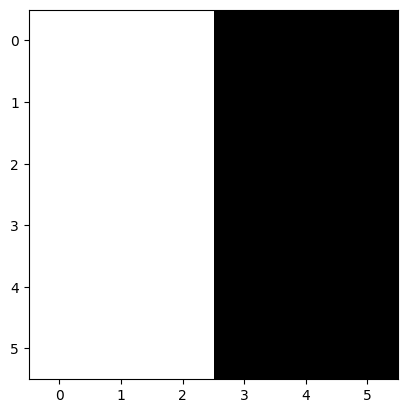

In [44]:
#Construyamos una imagen de negros y blancos
V = np.array([10,10,10,0,0,0])
Img = np.tile(V,6).reshape(6,6)
Img
plt.imshow(Img, cmap="gray")

 Detectemos los bordes con un filtro vertical
```
A = [[ 1  0 -1]
 [ 1  0 -1]
 [ 1  0 -1]]
 ```

[[ 1  0 -1]
 [ 1  0 -1]
 [ 1  0 -1]]


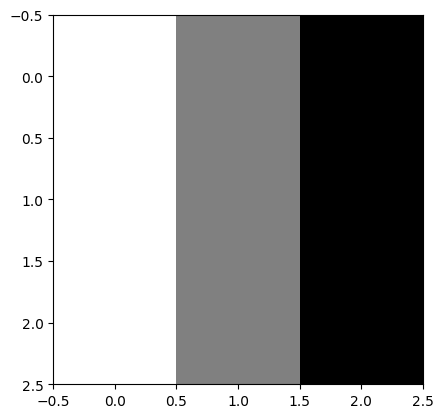

In [45]:
F = np.array([1,0,-1])
filter = np.tile(F,3).reshape(3,3)
print(filter)
plt.imshow(filter, cmap="gray")


La operación de convolución, permite construir una nueva matrix en la que se puede indentificar los bordes.

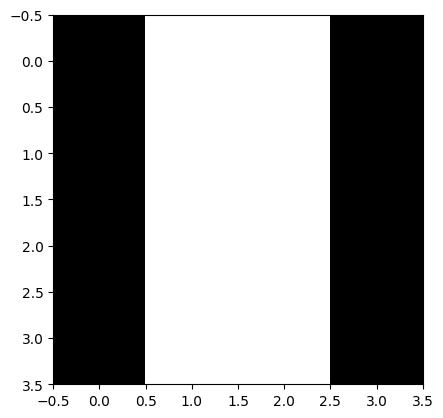

In [46]:
from scipy import signal
#new_img = np.convolve(Img, filter)
new_img = abs(signal.convolve2d(Img, filter, mode="valid"))

plt.figure()
plt.imshow(new_img, cmap="gray")
plt.show()


In [47]:
new_img

array([[ 0, 30, 30,  0],
       [ 0, 30, 30,  0],
       [ 0, 30, 30,  0],
       [ 0, 30, 30,  0]])

Apliquemos un filtro horizontal

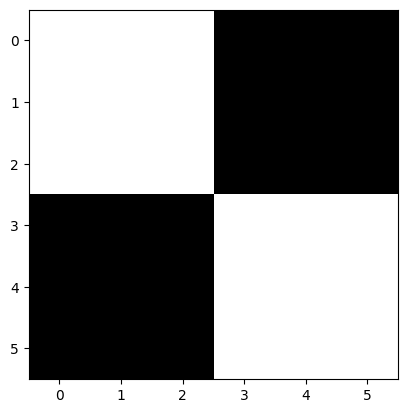

In [48]:
M = np.array([[10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0],
       [10, 10, 10,  0,  0,  0],
       [0, 0, 0,  10,  10,  10],
       [0, 0, 0,  10,  10,  10],
       [0, 0, 0,  10,  10,  10]])

plt.imshow(M, cmap="gray")

In [49]:
sp.Matrix(M)

Matrix([
[10, 10, 10,  0,  0,  0],
[10, 10, 10,  0,  0,  0],
[10, 10, 10,  0,  0,  0],
[ 0,  0,  0, 10, 10, 10],
[ 0,  0,  0, 10, 10, 10],
[ 0,  0,  0, 10, 10, 10]])

Matrix([
[ 1,  1,  1],
[ 0,  0,  0],
[-1, -1, -1]])

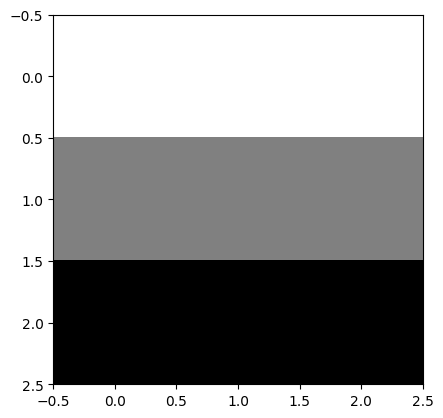

In [50]:
F = np.array([1,0,-1])
filter = np.tile(F,3).reshape(3,3)
filter=filter.T
#print(filter)
plt.imshow(filter, cmap="gray")
sp.Matrix(filter)

[[  0   0   0   0]
 [-30 -10  10  30]
 [-30 -10  10  30]
 [  0   0   0   0]]


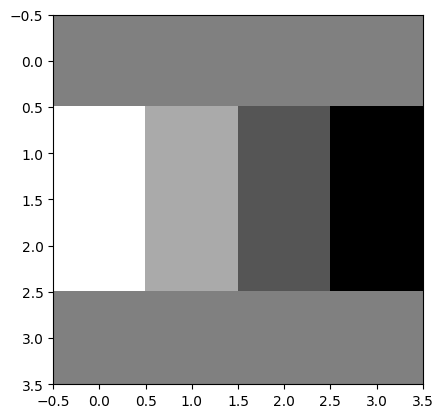

Matrix([
[ 0,  0,   0,   0],
[30, 10, -10, -30],
[30, 10, -10, -30],
[ 0,  0,   0,   0]])

In [51]:
new_img = signal.convolve2d(M,filter,mode="valid")
print(new_img)
plt.figure()
plt.imshow(-new_img, cmap="gray")
plt.show()
sp.Matrix(-new_img)


Existen otro tipo de filtros que pueden ser empleados.

- [Sobel filter](https://en.wikipedia.org/wiki/Sobel_operator)
  ```
  filter = array([[ 1,  0, -1],
       [ 2,  0, -2],
       [ 1,  0, -1]])
```
- Scharr Filter
```
filter = array([[ 3,  0, -3],
       [ 10,  0, -10],
       [ 3,  0, -3]])
```

¿Cómo elegir los parametros del filtro para detectar otro tipo de bordes?
```
filter = array([[ w1,  w2, w3],
     [ w4,  w5, w6],
     [ w7,  w8, w9]])
```

# Padding

El padding permite que la imagen resultante, sea del mismo tamaño que la original. Dada una matrix $n \times n$ asociada a una imagen y aplicada un filtro de rango $f\times f$ la operación después de la convolución es de rango $(n-f+1) \times (n-f+1)$.

Para garantizar que se tenga una imagen con el mismo tamaño de la original se aplica el padding



Para un padding de 1,tenemos entonces la siguientes dimensiones:

###  input = (n)x(n)


![input](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/input.png?raw=true)


### filter = fxf

![filter](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/filter.png?raw=true)



###  Output = (n-f+1)x(n-f+1)


![Output](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/output.png?raw=true)

--------------------------------------------------------------

 ### input con padding = (n+2p)x(n+2p)
![padding](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/padding.png?raw=true)



### filter = fxf

![filter](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/filter.png?raw=true)


###  Output = (n+2p-f+1)x(n+2p-f+1)




## Valid Padding

  - nxn * fxf ---> n-f+1

## Same Padding
The output size is the same that the input size

- n+2pxn+2p * fxf ---> n-f+1+2p x n-f+1+2p


# Stride

Salto entre valores de la imagen para hacer la convolución, en la siguiente imagen se muestra un stride de s=2.

Input : 6x6 = nxn

Filter : 3x3 = fxf

Results = Input * Filter

Results: (6-3)/2--->2x2

$\left[ \frac{n+2*p-f}{s}+1 \right] \times \left[ \frac{n+2*p-f}{s}+1 \right]$

[] operation floor


![stride](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/stride.png?raw=true)




# Convolución sobre todo el volumen:

![volumen](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/rgb_volume.png?raw=true)


## Multiples filtros sobre el volumen:


![multiples filtros](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/convolution_img/rgb_two_filter.png?raw=true)

Input= nxnxnc

Filter= fxfxnc

Output= n-f+1 x  n-f+1  x n'c

nc= numero de canales

n'c= el numero de filtros





REf: https://towardsdatascience.com/beginners-guide-to-understanding-convolutional-neural-networks-ae9ed58bb17d


# Clasificación de fases del modelo de Ising con una red convolucional (Keras)

Este laboratorio es análogo a `07_Lab_NN_IsingV2` (donde construimos un MLP), pero ahora usamos **Keras** — una API de más alto nivel — y una **red convolucional (CNN)** en lugar de un perceptrón multicapa.

Vamos a:

1. Hacer una introducción breve a Keras.
2. Cargar las configuraciones de espines del modelo de Ising (`Datos/ising_dataset.npz`).
3. Construir y entrenar una CNN simple que clasifique cada configuración como fase **ordenada** o **desordenada**.
4. Evaluarla sobre un barrido fino de temperaturas (`Datos/temperatura_critica.npz`) para **estimar la temperatura crítica** $T_c$ a partir de dónde la red cambia de opinión.
5. Bonus: usar la misma red, sin reentrenar, sobre configuraciones de **otro tamaño de red** ($L=20$, `Datos/temperatura_critica20.npz`).

## 0. ¿Qué es Keras?

**Keras** es una API de alto nivel para construir y entrenar redes neuronales. Desde la versión 3, Keras es *multi-backend*: el mismo código (`keras.layers`, `keras.Model`, `.compile()`, `.fit()`, ...) puede ejecutarse sobre **TensorFlow**, **JAX** o **PyTorch** como motor de cómputo. El backend se elige con la variable de entorno `KERAS_BACKEND` **antes** de importar `keras`; el resto del notebook no depende de cuál se use.

Comparado con lo que se hace  "a mano" en PyTorch, Keras encapsula el ciclo de entrenamiento:

| PyTorch (manual)                                              | Keras (equivalente)                    |
|---|---|
| Definir `Dataset` + `DataLoader`                               | Pasar arreglos de NumPy directamente a `.fit()` |
| Escribir el bucle `for epoch ... for batch ...`                | `model.fit(X, y, epochs=..., batch_size=...)` |
| `loss.backward()`, `optimizer.step()`, `optimizer.zero_grad()` | Ocurre internamente en `.fit()`        |
| Guardar el mejor modelo con un `if val_loss < best_val_loss`   | Callback `keras.callbacks.ModelCheckpoint` |
| `model.eval()` + `torch.no_grad()` + bucle manual              | `model.evaluate(X, y)` / `model.predict(X)` |

Un modelo en Keras se arma apilando **capas** (`keras.layers`) dentro de un `keras.Sequential` (o la API funcional para arquitecturas más complejas), se **compila** indicando optimizador, función de pérdida y métricas, y se **entrena** con `.fit()`.

In [52]:
import os
os.environ.setdefault("KERAS_BACKEND", "jax")  # TensorFlow, JAX o PyTorch: el código de Keras no cambia

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers

print("Keras:", keras.__version__)
print("Backend:", keras.backend.backend())

Keras: 3.13.2
Backend: jax


## 1. Datos: configuraciones de espines del modelo de Ising

Reutilizamos el dataset generado en `07_Lab_NN_IsingV2` (ver `07_bDatos_Ising.ipynb` para el detalle de cómo se generó). Cada configuración es una matriz $L\times L$ de espines $\pm 1$, etiquetada según su temperatura respecto a $T_c$:

| | fase **ordenada** (`y = 0`) | fase **desordenada** (`y = 1`) |
|---|---|---|
| temperatura | $T < T_c$ | $T > T_c$ |
| aspecto | un dominio grande domina la red | "ruido", sin dominios |

`ising_dataset.npz` **excluye** una banda alrededor de $T_c$ a propósito, para que las etiquetas sean inequívocas durante el entrenamiento.

In [53]:
# datos = np.load("Datos/ising_dataset.npz", allow_pickle=False)
from google.colab import drive
drive.mount('/content/drive')
datos = np.load("/content/drive/MyDrive/Datos/ising_dataset.npz", allow_pickle=False)

X = datos["X"]
y = datos["y"]
T = datos["T"]
m = datos["m"]
realizacion = datos["realizacion"]
Tc_onsager = float(datos["Tc"])
L = int(datos["L"])

print("X:", X.shape, X.dtype)
print("y:", y.shape, y.dtype)
print("Temperaturas:", np.unique(T))
print("Realizaciones:", np.unique(realizacion))
print(f"L = {L}   Tc (Onsager) = {Tc_onsager:.4f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
X: (1600, 16, 16) int8
y: (1600,) int8
Temperaturas: [1.2   1.375 1.55  1.725 1.9   2.6   2.825 3.05  3.275 3.5  ]
Realizaciones: [0 1 2 3]
L = 16   Tc (Onsager) = 2.2692


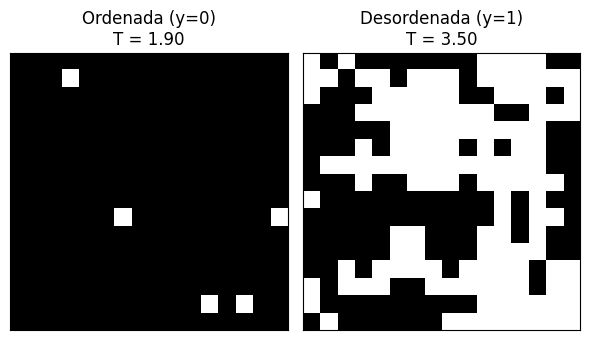

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(6, 6))

idx_ordenada = np.where(y == 0)[0][0]
idx_desordenada = np.where(y == 1)[0][0]

for ax, idx, titulo in zip(
    axes,
    [idx_ordenada, idx_desordenada],
    [f"Ordenada (y=0)\nT = {T[idx_ordenada]:.2f}", f"Desordenada (y=1)\nT = {T[idx_desordenada]:.2f}"],
):
    ax.imshow(X[idx], cmap="gray", vmin=-1, vmax=1)
    ax.set_title(titulo)
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

## 2. Preparación de los datos para Keras

Igual que en el notebook de PyTorch, usamos el campo `realizacion` (cadena de Monte Carlo independiente) para separar train/val/test, evitando que configuraciones muy correlacionadas de una misma cadena aparezcan en más de un conjunto:

- `realizacion` 0 y 1 → entrenamiento
- `realizacion` 2 → validación
- `realizacion` 3 → test

A diferencia del MLP (que aplanaba cada configuración a un vector de 256 valores), una CNN espera imágenes con forma `(alto, ancho, canales)`. Como tenemos un solo canal (el espín), reformamos cada configuración a `(L, L, 1)`. No hace falta convertir nada a tensores de PyTorch ni armar `DataLoader`s: Keras trabaja directamente con arreglos de NumPy.

In [55]:
mask_train = np.isin(realizacion, [0, 1])
mask_val = realizacion == 2
mask_test = realizacion == 3

def preparar(mask):
    X_ = X[mask].astype("float32").reshape(-1, L, L, 1)
    y_ = y[mask].astype("float32")
    T_ = T[mask]
    return X_, y_, T_

X_train, y_train, T_train = preparar(mask_train)
X_val, y_val, T_val = preparar(mask_val)
X_test, y_test, T_test = preparar(mask_test)

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape, y_val.shape)
print("Test: ", X_test.shape, y_test.shape)

Train: (800, 16, 16, 1) (800,)
Val:   (400, 16, 16, 1) (400,)
Test:  (400, 16, 16, 1) (400,)


## 3. Arquitectura: red convolucional simple

Una CNN es una elección natural para este problema: la fase de una configuración es una propiedad **estadística y global** (¿hay dominios grandes o no?), no depende de *dónde* aparezcan los dominios. Los filtros convolucionales detectan patrones locales (espines alineados con sus vecinos) **sin importar la posición**, exactamente la invariancia que necesitamos.

Arquitectura (deliberadamente simple):

- `Conv2D(8, 3x3) + ReLU` — detecta patrones locales de alineación.
- `MaxPooling2D(2x2)` — reduce la resolución espacial.
- `Conv2D(16, 3x3) + ReLU` — combina patrones locales en patrones un poco más grandes.
- `GlobalAveragePooling2D` — en vez de aplanar (`Flatten`) y usar una capa densa grande, promediamos cada mapa de activación sobre todo el espacio. Esto produce un vector de tamaño fijo **sin importar el tamaño $L\times L$ de la entrada**: la misma red podrá evaluarse más adelante sobre configuraciones de otro tamaño de red, algo que el MLP (con su entrada aplanada de tamaño fijo) no puede hacer.
- `Dense(16) + ReLU` y `Dense(1) + sigmoide` — combinan las características globales en una probabilidad de fase desordenada.

Para permitir tamaños de entrada variables declaramos `Input(shape=(None, None, 1))`.

In [56]:
keras.utils.set_random_seed(42)

model = keras.Sequential(
    [
        keras.Input(shape=(None, None, 1)),
        layers.Conv2D(8, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(16, 3, padding="same", activation="relu"),
        layers.GlobalAveragePooling2D(),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ],
    name="ising_cnn",
)

model.summary()

Model: "ising_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, None, None, 8)  │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, None, None, 8)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, None, None, 16) │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 16)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Compilación y entrenamiento

`compile()` fija el optimizador, la función de pérdida y las métricas a reportar. Como la última capa ya tiene activación sigmoide (produce una probabilidad), usamos `binary_crossentropy` directamente (en PyTorch usamos `BCEWithLogitsLoss` porque la red devolvía *logits*, no probabilidades).

El callback `ModelCheckpoint` guarda automáticamente los pesos con menor `val_loss`, reemplazando el bloque manual `if val_loss < best_val_loss: ...` del notebook de PyTorch.

In [57]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

checkpoint = keras.callbacks.ModelCheckpoint(
    "best_ising_cnn.keras",
    monitor="val_loss",
    save_best_only=True,
)

historia = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[checkpoint],
    verbose=2,
)

Epoch 1/20
25/25 - 3s - 116ms/step - accuracy: 0.8487 - loss: 0.5898 - val_accuracy: 1.0000 - val_loss: 0.4615
Epoch 2/20
25/25 - 0s - 6ms/step - accuracy: 1.0000 - loss: 0.3420 - val_accuracy: 0.9975 - val_loss: 0.2166
Epoch 3/20
25/25 - 0s - 6ms/step - accuracy: 1.0000 - loss: 0.1371 - val_accuracy: 1.0000 - val_loss: 0.0765
Epoch 4/20
25/25 - 0s - 6ms/step - accuracy: 1.0000 - loss: 0.0512 - val_accuracy: 1.0000 - val_loss: 0.0335
Epoch 5/20
25/25 - 0s - 6ms/step - accuracy: 1.0000 - loss: 0.0246 - val_accuracy: 1.0000 - val_loss: 0.0195
Epoch 6/20
25/25 - 0s - 6ms/step - accuracy: 1.0000 - loss: 0.0160 - val_accuracy: 0.9975 - val_loss: 0.0144
Epoch 7/20
25/25 - 0s - 6ms/step - accuracy: 1.0000 - loss: 0.0108 - val_accuracy: 1.0000 - val_loss: 0.0103
Epoch 8/20
25/25 - 0s - 6ms/step - accuracy: 1.0000 - loss: 0.0082 - val_accuracy: 1.0000 - val_loss: 0.0087
Epoch 9/20
25/25 - 0s - 6ms/step - accuracy: 1.0000 - loss: 0.0068 - val_accuracy: 1.0000 - val_loss: 0.0074
Epoch 10/20
25/25

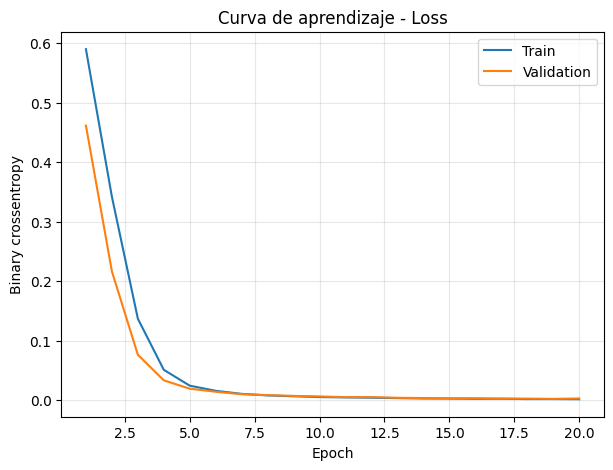

In [58]:
epochs_range = range(1, len(historia.history["loss"]) + 1)

plt.figure(figsize=(7, 5))
plt.plot(epochs_range, historia.history["loss"], label="Train")
plt.plot(epochs_range, historia.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Binary crossentropy")
plt.title("Curva de aprendizaje - Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

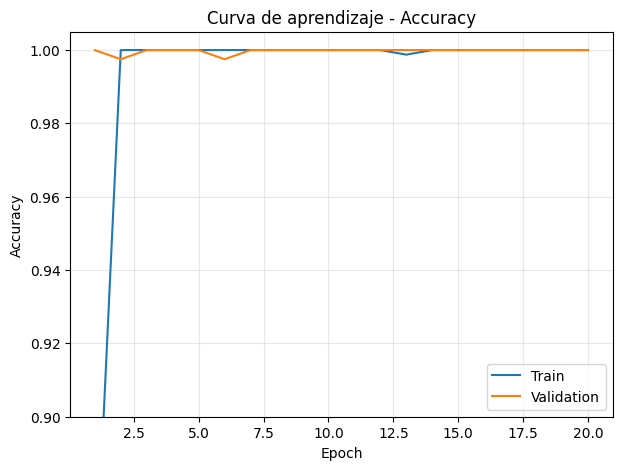

In [59]:
plt.figure(figsize=(7, 5))
plt.plot(epochs_range, historia.history["accuracy"], label="Train")
plt.plot(epochs_range, historia.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Curva de aprendizaje - Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.ylim(0.9, 1.005)
plt.show()

## 5. Evaluación en el conjunto de test

In [60]:
model = keras.models.load_model("best_ising_cnn.keras")

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss:     {test_loss:.5f}")
print(f"Test accuracy: {test_acc:.4f}")

Test loss:     0.00321
Test accuracy: 1.0000


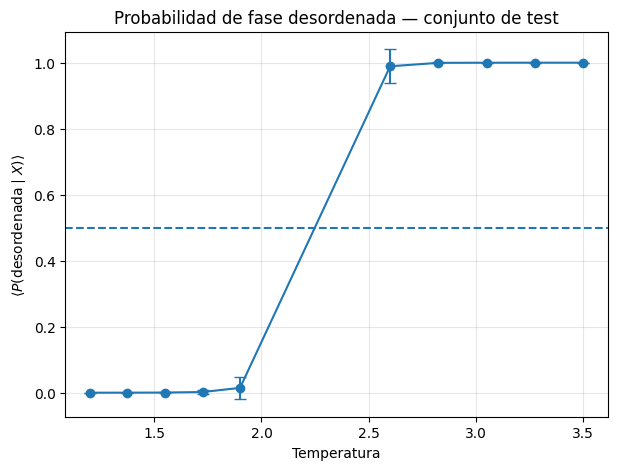

In [61]:
probs_test = model.predict(X_test, verbose=0).ravel()

unique_T_test = np.unique(T_test)
mean_p, std_p = [], []
for temp in unique_T_test:
    mask = T_test == temp
    mean_p.append(probs_test[mask].mean())
    std_p.append(probs_test[mask].std())
mean_p, std_p = np.array(mean_p), np.array(std_p)

plt.figure(figsize=(7, 5))
plt.errorbar(unique_T_test, mean_p, yerr=std_p, fmt="o-", capsize=4)
plt.axhline(0.5, linestyle="--")
plt.xlabel("Temperatura")
plt.ylabel(r"$\langle P(\mathrm{desordenada} \mid X)\rangle$")
plt.title("Probabilidad de fase desordenada — conjunto de test")
plt.grid(alpha=0.3)
plt.show()

## 6. Barrido cerca de la temperatura crítica

`ising_dataset.npz` deja fuera a propósito una banda alrededor de $T_c$. `temperatura_critica.npz` es el conjunto contrario: un barrido fino que **sí incluye** la zona crítica, con varias realizaciones independientes. Aquí no hay etiqueta de entrenamiento confiable — la idea es que, si la red aprendió a reconocer fases, su probabilidad promedio $\langle P(\mathrm{desordenada}\mid T)\rangle$ pase de 0 a 1 alrededor de la verdadera $T_c$, y podamos **estimar $T_c$ como el punto donde esa curva cruza 0.5**.

In [62]:
# datos_tc = np.load("Datos/temperatura_critica.npz", allow_pickle=False)
from google.colab import drive
drive.mount('/content/drive')
datos_tc = np.load("/content/drive/MyDrive/Datos/temperatura_critica.npz", allow_pickle=False)

X_tc = datos_tc["X"].astype("float32").reshape(-1, L, L, 1)
T_tc = datos_tc["T"]
realizacion_tc = datos_tc["realizacion"]

print("X_tc:", X_tc.shape)
print("Temperaturas:", np.unique(T_tc))
print("Realizaciones:", np.unique(realizacion_tc))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
X_tc: (6200, 16, 16, 1)
Temperaturas: [1.6   1.7   1.8   1.9   2.    2.05  2.075 2.1   2.125 2.15  2.175 2.2
 2.225 2.25  2.275 2.3   2.325 2.35  2.375 2.4   2.425 2.45  2.475 2.5
 2.6   2.7   2.8   2.9   3.    3.1   3.2  ]
Realizaciones: [0 1 2 3]


In [63]:
probs_tc = model.predict(X_tc, verbose=0).ravel()
pred_tc = (probs_tc >= 0.5).astype(int)

df = pd.DataFrame({
    "T": T_tc,
    "realizacion": realizacion_tc,
    "probabilidad": probs_tc,
    "prediccion": pred_tc,
})

resumen = (
    df.groupby(["realizacion", "T"])
      .agg(prob_media=("probabilidad", "mean"), prob_std=("probabilidad", "std"), N=("prediccion", "size"))
      .reset_index()
)

resumen.head(10)

,realizacion,T,prob_media,prob_std,N
0,0,1.600,0.000435,0.000341,50
1,0,1.700,0.001301,0.002158,50
2,0,1.800,0.002337,0.004612,50
3,0,1.900,0.004350,0.006657,50
4,0,2.000,0.021877,0.047564,50
5,0,2.050,0.113461,0.192206,50
6,0,2.075,0.077053,0.126211,50
7,0,2.100,0.075800,0.137167,50
8,0,2.125,0.193400,0.302327,50
9,0,2.150,0.241184,0.313026,50


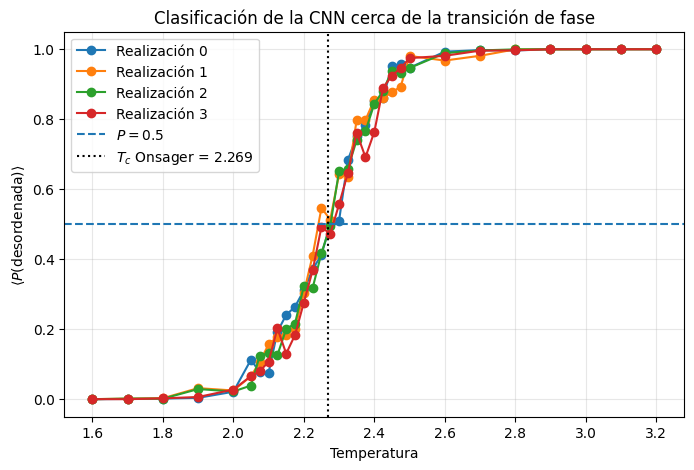

In [64]:
plt.figure(figsize=(8, 5))

for r in np.unique(realizacion_tc):
    datos_r = resumen[resumen["realizacion"] == r]
    plt.plot(datos_r["T"], datos_r["prob_media"], "o-", label=f"Realización {r}")

plt.axhline(0.5, linestyle="--", label=r"$P=0.5$")
plt.axvline(Tc_onsager, linestyle=":", color="k", label=fr"$T_c$ Onsager = {Tc_onsager:.3f}")

plt.xlabel("Temperatura")
plt.ylabel(r"$\langle P(\mathrm{desordenada})\rangle$")
plt.title("Clasificación de la CNN cerca de la transición de fase")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [65]:
Tc_estimadas = []

for r in np.unique(realizacion_tc):
    datos_r = resumen[resumen["realizacion"] == r].sort_values("T")
    temps = datos_r["T"].to_numpy()
    probs = datos_r["prob_media"].to_numpy()

    for i in range(len(temps) - 1):
        p1, p2 = probs[i], probs[i + 1]
        if p1 <= 0.5 <= p2:
            T1, T2 = temps[i], temps[i + 1]
            Tc_r = T1 + (0.5 - p1) * (T2 - T1) / (p2 - p1)  # interpolación lineal
            Tc_estimadas.append(Tc_r)
            print(f"Realización {r}: Tc_CNN = {Tc_r:.4f}")
            break

Tc_estimadas = np.array(Tc_estimadas)
Tc_mean = Tc_estimadas.mean()
Tc_std = Tc_estimadas.std(ddof=1)

print()
print(f"Tc_CNN promedio = {Tc_mean:.4f} +/- {Tc_std:.4f}")
print(f"Tc Onsager      = {Tc_onsager:.4f}")

Realización 0: Tc_CNN = 2.2759
Realización 1: Tc_CNN = 2.2414
Realización 2: Tc_CNN = 2.2757
Realización 3: Tc_CNN = 2.2832

Tc_CNN promedio = 2.2691 +/- 0.0188
Tc Onsager      = 2.2692


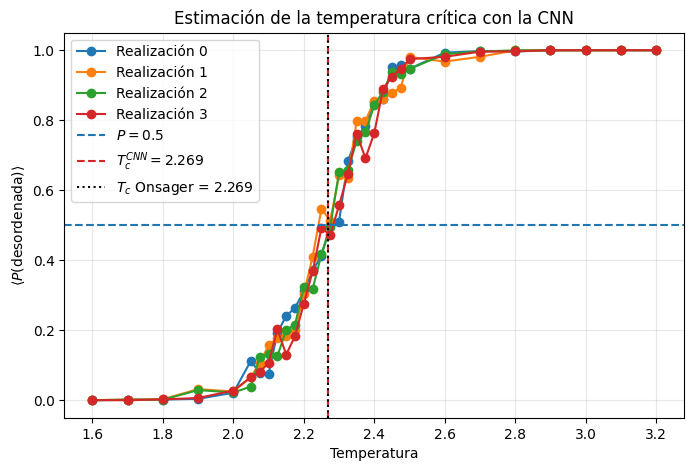

In [66]:
plt.figure(figsize=(8, 5))

for r in np.unique(realizacion_tc):
    datos_r = resumen[resumen["realizacion"] == r]
    plt.plot(datos_r["T"], datos_r["prob_media"], "o-", label=f"Realización {r}")

plt.axhline(0.5, linestyle="--", label=r"$P=0.5$")
plt.axvline(Tc_mean, linestyle="--", color="C3", label=fr"$T_c^{{CNN}} = {Tc_mean:.3f}$")
plt.axvline(Tc_onsager, linestyle=":", color="k", label=fr"$T_c$ Onsager = {Tc_onsager:.3f}")

plt.xlabel("Temperatura")
plt.ylabel(r"$\langle P(\mathrm{desordenada})\rangle$")
plt.title("Estimación de la temperatura crítica con la CNN")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Bonus: generalización a otro tamaño de red ($L=20$)

`GlobalAveragePooling2D` hace que la red no tenga ningún peso atado a un tamaño de entrada específico. Podemos entonces tomar exactamente el mismo modelo, **sin reentrenar**, y evaluarlo sobre `temperatura_critica20.npz` (configuraciones $20\times 20$, con la misma $T_c$ física). Con un MLP de entrada aplanada esto sería imposible sin cambiar la arquitectura.

In [67]:
# datos_tc20 = np.load("Datos/temperatura_critica20.npz", allow_pickle=False)

from google.colab import drive
drive.mount('/content/drive')
datos_tc20 = np.load("/content/drive/MyDrive/Datos/temperatura_critica20.npz", allow_pickle=False)

L20 = int(datos_tc20["L"])

X_tc20 = datos_tc20["X"].astype("float32").reshape(-1, L20, L20, 1)
T_tc20 = datos_tc20["T"]
realizacion_tc20 = datos_tc20["realizacion"]

print(f"L = {L20}   X_tc20: {X_tc20.shape}")

probs_tc20 = model.predict(X_tc20, verbose=0).ravel()

df20 = pd.DataFrame({
    "T": T_tc20,
    "realizacion": realizacion_tc20,
    "probabilidad": probs_tc20,
})

resumen20 = (
    df20.groupby("T")
        .agg(prob_media=("probabilidad", "mean"), prob_std=("probabilidad", "std"))
        .reset_index()
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
L = 20   X_tc20: (6200, 20, 20, 1)


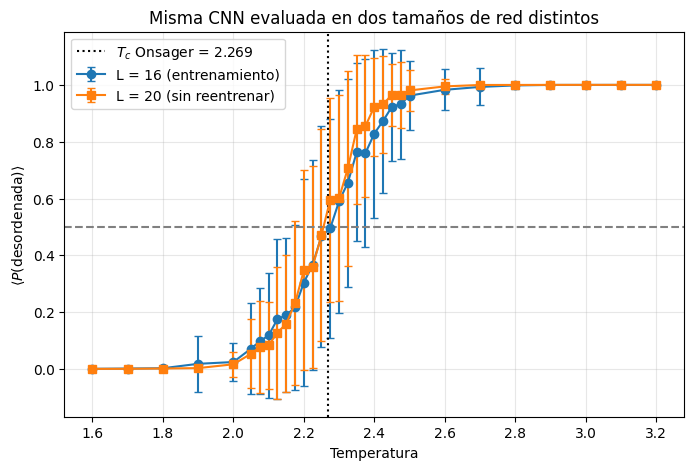

In [68]:
resumen16 = (
    df.groupby("T")
      .agg(prob_media=("probabilidad", "mean"), prob_std=("probabilidad", "std"))
      .reset_index()
)

plt.figure(figsize=(8, 5))

plt.errorbar(resumen16["T"], resumen16["prob_media"], yerr=resumen16["prob_std"],
             fmt="o-", capsize=3, label=f"L = {L} (entrenamiento)")
plt.errorbar(resumen20["T"], resumen20["prob_media"], yerr=resumen20["prob_std"],
             fmt="s-", capsize=3, label=f"L = {L20} (sin reentrenar)")

plt.axhline(0.5, linestyle="--", color="gray")
plt.axvline(Tc_onsager, linestyle=":", color="k", label=fr"$T_c$ Onsager = {Tc_onsager:.3f}")

plt.xlabel("Temperatura")
plt.ylabel(r"$\langle P(\mathrm{desordenada})\rangle$")
plt.title("Misma CNN evaluada en dos tamaños de red distintos")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Para una red más grande ($L=20$) se espera que la transición se vea **más abrupta** (más cercana al límite termodinámico, donde la transición de fase es discontinua), mientras que en $L=16$ el efecto de tamaño finito la suaviza un poco. Aun así, la misma CNN — sin ver un solo ejemplo de $L=20$ durante el entrenamiento — debería ubicar el cruce cerca de $T_c$.


- Keras permite construir y entrenar la misma clase de clasificador que hicimos con PyTorch en muchas menos líneas: no hay bucle de entrenamiento manual, `DataLoader` ni manejo explícito del dispositivo.
- Una CNN simple (dos capas convolucionales + *global average pooling*) alcanza una exactitud muy alta separando fase ordenada vs. desordenada lejos de $T_c$.
- Evaluando la red sobre el barrido fino de temperaturas, la probabilidad de fase desordenada cruza $0.5$ muy cerca de la $T_c$ de Onsager, sin que la red haya visto nunca esa temperatura durante el entrenamiento.
- Gracias a `GlobalAveragePooling2D`, la arquitectura no depende del tamaño $L\times L$ de la red de espines, lo que permite reutilizar el mismo modelo entrenado sobre configuraciones de otro tamaño — algo que un MLP con entrada aplanada no puede hacer sin cambiar de arquitectura.

# Laboratorio: interpreta la red, no solo confíes en ella

La CNN clasifica fases con exactitud casi perfecta y ubica $T_c$ con buena precisión. Eso no basta: una red puede acertar por razones equivocadas (un atajo espurio en los datos, por ejemplo). Antes de dar el resultado por bueno, ábrela:

- Estudia los kernels de la primera capa convolucional. ¿Qué patrón detecta cada uno? Compáralos con un kernel de "vecinos cercanos" (como el acoplamiento del Hamiltoniano de Ising) y con un kernel de "promedio local" (un detector de magnetización). ¿Se parece alguno a estos kernels físicos, o la red encontró otra cosa?


- Analiza los mapas de activación de esos filtros sobre una configuración ordenada y una desordenada. ¿La diferencia visual que ves coincide con lo que dirías tú, a ojo, si miraras las dos configuraciones sin saber la respuesta?


- Mide qué tan sensible es la red a voltear un solo espín, lejos de $T_c$ y cerca de $T_c$. ¿Dónde es más sensible? ¿Se te ocurre una razón física para eso?

$$S(x) = \frac{1}{L^2}\sum_{i=1}^{L^2} \big|\Delta P_i(x)\big|, \qquad \Delta P_i(x) = P(\text{config. con } s_i \text{ volteado}) - P(x)$$


- Verifica si el logit ($z = Wx+b$) final es, en el fondo, una función de la magnetización. Grafica el logit contra $|m(x)|$, antes y después de entrenar. ¿La red "redescubrió" el parámetro de orden por su cuenta, o el resultado depende de trucos de la arquitectura?

**1. Estudio de los kernels de la primera capa convolucional.**

In [69]:
# Inspeccionar las capas para saber el índice de la primera conv
for i, layer in enumerate(model.layers):
    print(f"[{i}] {layer.name:30s} ({layer.__class__.__name__})")

[0] conv2d_2                       (Conv2D)
[1] max_pooling2d_1                (MaxPooling2D)
[2] conv2d_3                       (Conv2D)
[3] global_average_pooling2d_1     (GlobalAveragePooling2D)
[4] dense_2                        (Dense)
[5] dense_3                        (Dense)


In [70]:
conv1 = model.layers[0]
kernels, biases = conv1.get_weights()

print("Kernels shape:", kernels.shape)   # (3, 3, 1, 8)
print("Biases shape: ", biases.shape)    # (8,)

Kernels shape: (3, 3, 1, 8)
Biases shape:  (8,)


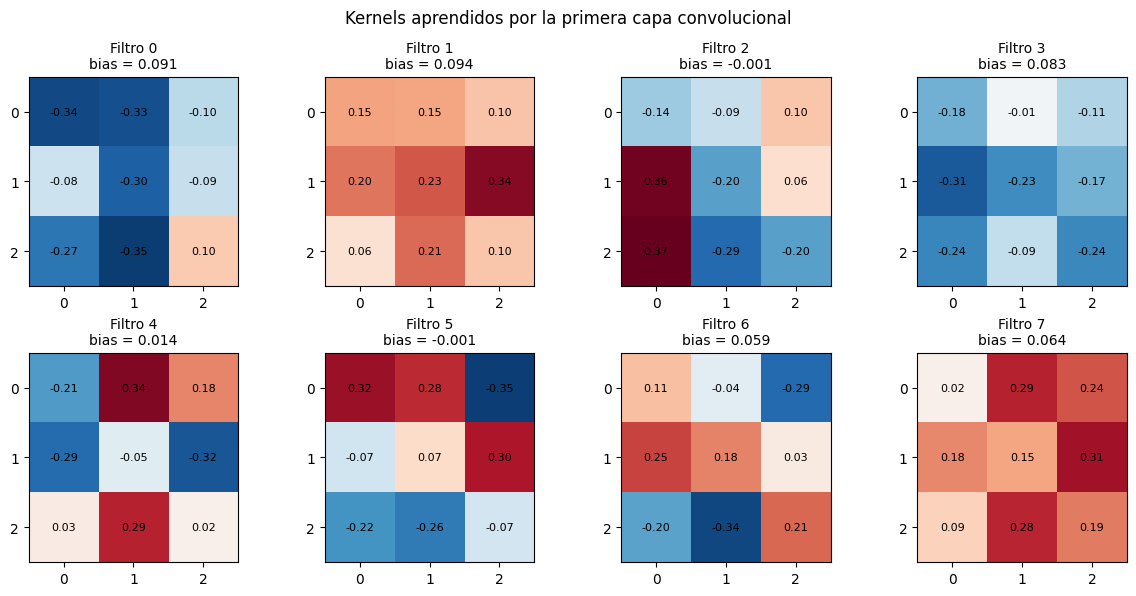

In [71]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
vmax = np.abs(kernels).max()

for i, ax in enumerate(axes.ravel()):
    k = kernels[:, :, 0, i]
    ax.imshow(k, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_title(f"Filtro {i}\nbias = {biases[i]:.3f}", fontsize=10)
    ax.set_xticks([0, 1, 2]); ax.set_yticks([0, 1, 2])

    for r in range(3):
        for c in range(3):
            ax.text(c, r, f"{k[r, c]:.2f}", ha="center", va="center", fontsize=8)

plt.suptitle("Kernels aprendidos por la primera capa convolucional", fontsize=12)
plt.tight_layout()
plt.show()

In [73]:
kernels_fisicos = {
    # Vecinos más cercanos del Hamiltoniano de Ising
    # Detecta "alineación local": si los 4 vecinos son iguales al centro → suma alta
    "Ising (vecinos)": np.array([
        [0, 1, 0],
        [1, 0, 1],
        [0, 1, 0],
    ], dtype=np.float32),

    # Laplaciano: el negativo mide "desalineación local" (energía de Ising)
    # -4 * centro + suma de los 4 vecinos = "qué tan distinto es el centro de sus vecinos"
    "Laplaciano": np.array([
        [0,  1, 0],
        [1, -4, 1],
        [0,  1, 0],
    ], dtype=np.float32),

    # Promedio local = detector de magnetización
    "Promedio local": np.ones((3, 3), dtype=np.float32) / 9,

    # Detector de borde vertical (Prewitt)
    "Borde vertical": np.array([
        [ 1, 0, -1],
        [ 1, 0, -1],
        [ 1, 0, -1],
    ], dtype=np.float32),

    # Detector de borde horizontal
    "Borde horizontal": np.array([
        [ 1,  1,  1],
        [ 0,  0,  0],
        [-1, -1, -1],
    ], dtype=np.float32),
}

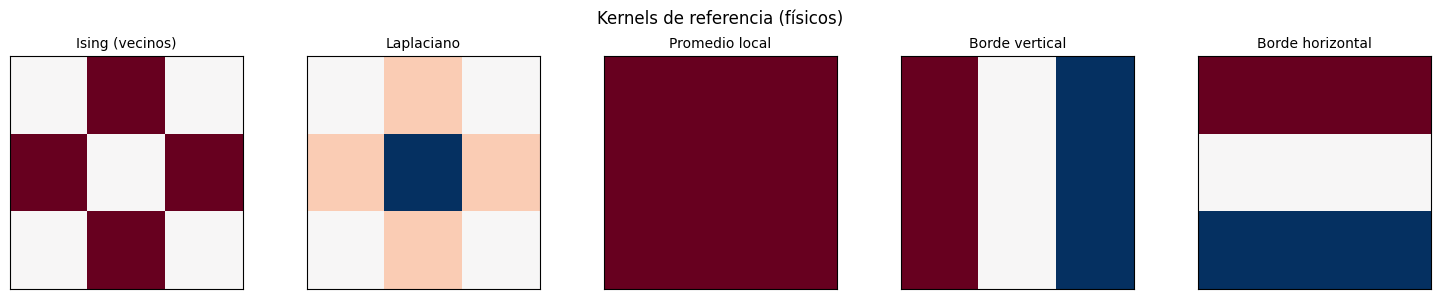

In [74]:
# 1) Graficar los físicos
fig, axes = plt.subplots(1, len(kernels_fisicos), figsize=(15, 3))
for ax, (nombre, K) in zip(axes, kernels_fisicos.items()):
    vmax = np.abs(K).max()
    ax.imshow(K, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_title(nombre, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Kernels de referencia (físicos)", fontsize=12)
plt.tight_layout()
plt.show()

In [75]:
def cos_sim(a, b):
    """Similitud coseno entre dos kernels aplanados. Va de -1 a +1."""
    a, b = a.flatten(), b.flatten()
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12)

# Encabezado
print(f"{'':>12}", end="")
for nombre in kernels_fisicos:
    print(f"{nombre[:14]:>16}", end="")
print()

# Filas
for i in range(8):
    k = kernels[:, :, 0, i]
    print(f"Filtro {i:>3}: ", end="")
    for nombre, kf in kernels_fisicos.items():
        sim = cos_sim(k, kf)
        print(f"{sim:>16.3f}", end="")
    print()

              Ising (vecinos      Laplaciano  Promedio local  Borde vertical  Borde horizont
Filtro   0:           -0.573           0.113          -0.795          -0.330          -0.133
Filtro   1:            0.790          -0.010           0.907          -0.100           0.022
Filtro   2:            0.033           0.278          -0.009           0.375          -0.000
Filtro   3:           -0.497           0.127          -0.896          -0.143           0.188
Filtro   4:            0.017           0.068          -0.002          -0.209          -0.010
Filtro   5:            0.166          -0.009          -0.007           0.085           0.452
Filtro   6:           -0.074          -0.295          -0.038           0.133           0.069
Filtro   7:            0.824           0.163           0.902          -0.292          -0.015


## Interpretación de los kernels de la primera capa convolucional

Al comparar los 8 filtros aprendidos con kernels de referencia físicos (similitud coseno), se observa:

- **Filtros 1 y 7** (sim ≈ 0.90 con el promedio local): detectan magnetización local, el parámetro de orden del modelo de Ising.
- **Filtros 0 y 3** (sim ≈ −0.85 con el promedio local): miden lo mismo pero con signo opuesto, reflejando la simetría $s \to -s$ del Hamiltoniano.
- **Filtros 2 y 6** (sim ≈ ±0.30 con el laplaciano): tienen componente de energía local (alineación centro-vecinos), aunque combinada con otros patrones.
- **Filtro 5** (sim ≈ 0.45 con borde horizontal): detecta paredes de dominio.
- **Filtro 4**: no se parece a ningún kernel físico simple; captura una combinación abstracta.

Esto muestra que la red sí aprendió kernels con sentido físico, no encontró "otra cosa". Cuatro de sus ocho filtros miden magnetización local, dos tienen componente de energía local y uno detecta bordes de dominio. Es decir, la red redescubrió por su cuenta las dos cantidades que la teoría predice como relevantes para la transición de fase: magnetización y energía local.

**2. Analisis de los mapas de activación de los filtros**

In [76]:
# Modelo que devuelve la salida de la primera conv
intermediate = keras.Model(
    inputs=model.inputs,
    outputs=model.layers[0].output
)

# Tomar una configuración ordenada y una desordenada
idx_ord = np.where(y == 0)[0][0]
idx_des = np.where(y == 1)[0][0]

X_ord = X[idx_ord].astype("float32").reshape(1, L, L, 1)
X_des = X[idx_des].astype("float32").reshape(1, L, L, 1)

activ_ord = intermediate.predict(X_ord, verbose=0)[0]   # (L, L, 8)
activ_des = intermediate.predict(X_des, verbose=0)[0]

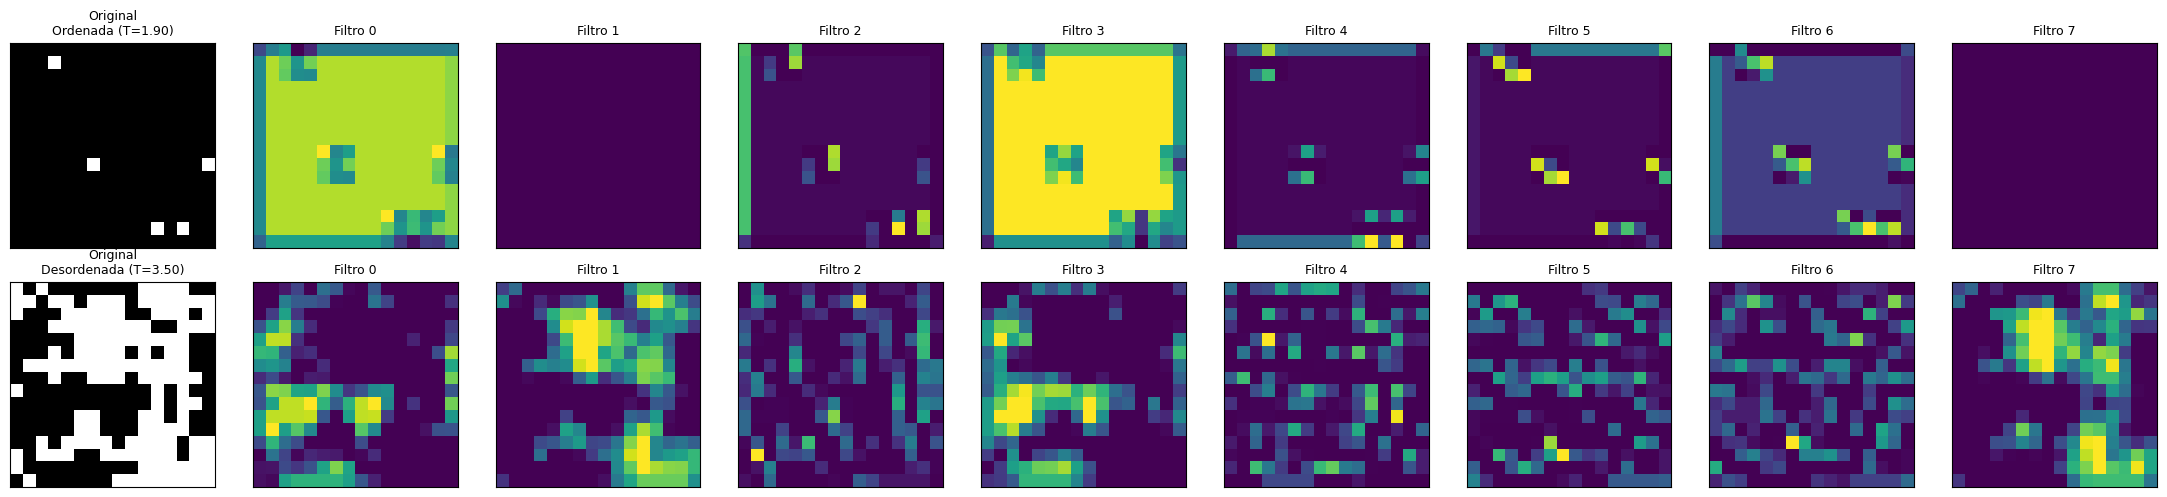

In [77]:
fig, axes = plt.subplots(2, 9, figsize=(22, 5))

for row, (config, activ, titulo) in enumerate([
    (X_ord[0, :, :, 0], activ_ord, f"Ordenada (T={T[idx_ord]:.2f})"),
    (X_des[0, :, :, 0], activ_des, f"Desordenada (T={T[idx_des]:.2f})"),
]):
    # Configuración original
    axes[row, 0].imshow(config, cmap="gray", vmin=-1, vmax=1)
    axes[row, 0].set_title(f"Original\n{titulo}", fontsize=9)
    axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])

    # 8 mapas de activación
    for i in range(8):
        axes[row, i+1].imshow(activ[:, :, i], cmap="viridis")
        axes[row, i+1].set_title(f"Filtro {i}", fontsize=9)
        axes[row, i+1].set_xticks([]); axes[row, i+1].set_yticks([])

plt.tight_layout()
plt.show()

## Interpretación de los mapas de activación

Se graficaron los mapas de la primera capa convolucional sobre una configuración
ordenada (T = 1.90) y una desordenada (T = 3.50).

- **Filtros de magnetización (0, 1, 3, 7):** sobre la ordenada dan mapas planos
  (magnetización uniforme); sobre la desordenada dan mosaicos con zonas claras y oscuras (fluctuaciones locales). La diferencia "plano vs rugoso" es la firma visual de las dos fases.

- **Filtros de energía local (2, 6):** sobre la ordenada se activan solo en los pocos  defectos puntuales; sobre la desordenada se activan en todo el espacio. Confirma  que miden desalineación local (energía de Ising).

- **Filtro de bordes (5):** pocos puntos activos en la ordenada, muchos segmentos dispersos  en la desordenada (más paredes de dominio).

- **Filtro 4:** sin patrón claro, probablemente se combina con otros en capas posteriores.

La diferencia visual coincide con lo que uno diría a ojo.
Mirando las dos configuraciones sin etiquetas, un humano usaría las mismas estrategias que la red: buscar dominios grandes en la ordenada, y fluctuaciones o paredes de dominio dispersas en la desordenada. Los filtros reflejan la estrategia visual del físico; no hay patrones espurios ni atajos ocultos.

**3. Sensibilidad**

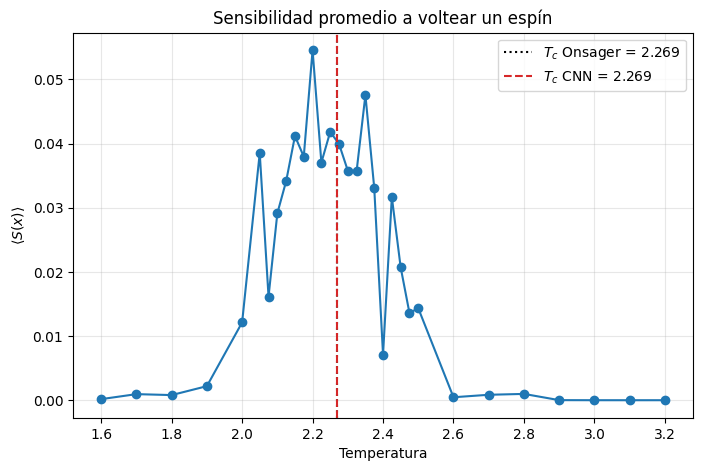

In [78]:
# ============================================================
#           Sensibilidad a voltear un solo espín
# ============================================================

def sensibilidad_promedio(model, x, n_espines=64, seed=42):
    """
    Calcula S(x) para una configuración, promediando sobre n_espines
    espines aleatorios (no todos, para ir más rápido).
    """
    rng = np.random.default_rng(seed)
    L = x.shape[0]
    x_tensor = x.astype("float32").reshape(1, L, L, 1)
    p_orig = float(model.predict(x_tensor, verbose=0)[0, 0])

    # Elegir n_espines posiciones al azar
    idxs = rng.choice(L * L, size=n_espines, replace=False)

    # Generar todas las configuraciones con un espín volteado
    X_flip = np.zeros((n_espines, L, L, 1), dtype="float32")
    for k, idx in enumerate(idxs):
        r, c = divmod(idx, L)
        f = x.copy()
        f[r, c] *= -1
        X_flip[k, :, :, 0] = f

    # Predecir todas a la vez
    p_flip = model.predict(X_flip, verbose=0).ravel()

    # S(x)
    return np.abs(p_flip - p_orig).mean()


# --- Calcular S(T) sobre el barrido cerca de Tc ---
np.random.seed(42)
T_unicas = np.unique(T_tc)
S_por_T = []

for temp in T_unicas:
    idxs = np.where(T_tc == temp)[0][:10]  # 10 configs por temperatura
    Ss = []
    for idx in idxs:
        x = datos_tc["X"][idx].astype("float32")
        Ss.append(sensibilidad_promedio(model, x, n_espines=64))
    S_por_T.append(np.mean(Ss))

# --- Graficar ---
plt.figure(figsize=(8, 5))
plt.plot(T_unicas, S_por_T, "o-", color="C0")
plt.axvline(Tc_onsager, linestyle=":",  color="k",  label=f"$T_c$ Onsager = {Tc_onsager:.3f}")
plt.axvline(Tc_mean,    linestyle="--", color="C3", label=f"$T_c$ CNN = {Tc_mean:.3f}")
plt.xlabel("Temperatura")
plt.ylabel(r"$\langle S(x) \rangle$")
plt.title("Sensibilidad promedio a voltear un espín")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Sensibilidad a voltear un espín

Se calculó $S(x)$ para 10 configuraciones a cada temperatura del barrido, promediando sobre 64 espines por configuración.

**Resultado**: la curva $S(T)$ presenta un pico claro cerca de $T_c$ (máximo ~0.055 en T ≈ 2.22), con valores prácticamente nulos lejos de la transición (T < 2.0 y T > 2.6).

**Razón física**: cerca de $T_c$ la longitud de correlación diverge, cada espín
está correlacionado con muchos otros lejanos, así que voltear un solo espín puede propagar su efecto por toda la red y cambiar la clasificación global. Lejos de $T_c$, la correlación es de corto alcance: voltear un espín solo afecta a su vecindario, y la red mantiene su predicción porque mira el comportamiento global.

Es el análogo computacional de la susceptibilidad magnética $\chi$, que también
diverge en $T_c$: la red es más "sensible" a perturbaciones cuando el sistema físico está en la zona crítica.

**4. Verificar si el logit ($z = Wx+b$) final es, en el fondo, una función de la magnetización.**

logit_entrenado: (1600,)
logit_aleatorio: (1600,)


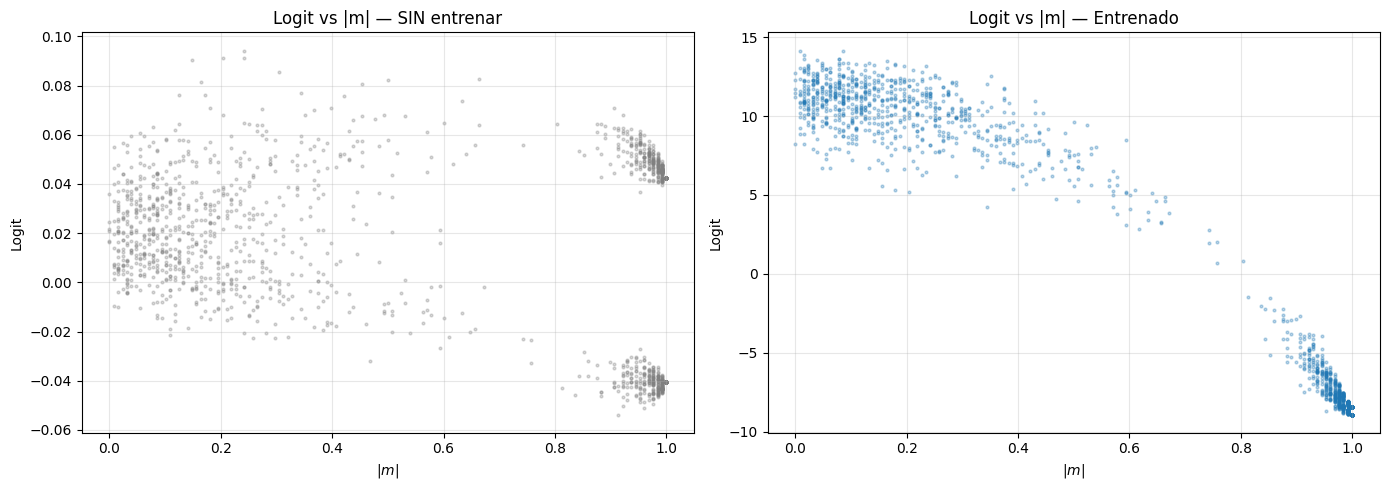

In [84]:
# --- Paso 4: obtener el logit del modelo ENTRENADO (Opción A: desde la probabilidad) ---
p_entrenado = model.predict(X_all, batch_size=256, verbose=0).ravel()
p_entrenado = np.clip(p_entrenado, 1e-7, 1 - 1e-7)
logit_entrenado = np.log(p_entrenado / (1 - p_entrenado))
print("logit_entrenado:", logit_entrenado.shape)   # → (1600,)

# --- Paso 5: obtener el logit del modelo SIN entrenar (Opción A) ---
p_aleatorio = model_rand.predict(X_all, batch_size=256, verbose=0).ravel()
p_aleatorio = np.clip(p_aleatorio, 1e-7, 1 - 1e-7)
logit_aleatorio = np.log(p_aleatorio / (1 - p_aleatorio))
print("logit_aleatorio:", logit_aleatorio.shape)   # → (1600,)

# --- Paso 6: graficar ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(m_abs, logit_aleatorio, s=4, alpha=0.3, c="gray")
axes[0].set_xlabel(r"$|m|$")
axes[0].set_ylabel("Logit")
axes[0].set_title("Logit vs |m| — SIN entrenar")
axes[0].grid(alpha=0.3)

axes[1].scatter(m_abs, logit_entrenado, s=4, alpha=0.3, c="C0")
axes[1].set_xlabel(r"$|m|$")
axes[1].set_ylabel("Logit")
axes[1].set_title("Logit vs |m| — Entrenado")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## ¿El logit es función de la magnetización?

Se graficó el logit (log-odds de la probabilidad predicha) contra la magnetización absoluta $|m|$ de cada configuración, para un modelo entrenado y uno con pesos aleatorios.

- **Sin entrenar**: nube dispersa, sin relación con $|m|$. Logits acotados a ~0.1.  La arquitectura por sí sola no impone ninguna noción de magnetización.

- **Entrenado**: los puntos colapsan en una curva monótona decreciente que va
  desde logit ≈ +13 para $|m| \approx 0$ (fase desordenada) hasta logit ≈ -9 para
  $|m| \approx 1$ (fase ordenada). La transición ocurre alrededor de $|m| \approx 0.5$.

La red sí redescubrió el parámetro de orden por su
cuenta. No recibe $|m|$ como input, y la arquitectura con pesos aleatorios no
muestra ninguna relación logit–$|m|$; solo después del entrenamiento emerge la curva.